# Quick checks: selected compact models
TRAIN probability quantiles define fixed decile cutoffs for every set. ECE = sum over bins of (bin sample count / set sample count) × |mean probability − observed positive rate|. Brier = mean((p−y)²). Repeated quantiles are merged, so tied predictions can yield fewer than ten occupied bins. End bins cover [0,1]. No model fitting or probability calibration is performed. Regression compares actual and predicted future MA5 aligned to decision time. TRAIN is in-sample; OOT dates were inspected previously.

In [1]:
from pathlib import Path
import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
P=Path.cwd(); ROOT=P.parent
OUT=P/'calibration_checks'; OUT.mkdir(exist_ok=True)
d=pd.read_csv(ROOT/'Dataset_X_y.csv.gz',low_memory=False)
time=pd.to_datetime(d.decision_at,utc=True).dt.tz_convert('Asia/Bangkok')
schedule=pd.read_csv(ROOT/'Schedule.csv')
ids={r.partition:np.flatnonzero(time.between(pd.Timestamp(r.first),pd.Timestamp(r.last)) & d.eligible) for r in schedule.itertuples()}
summary=[]; bins=[]; cutoff_rows=[]
def predict(h,task,part):
    bundle=pickle.load((P/f'h{h}_{task}_compact.pkl').open('rb'))
    i=ids[part]; names=bundle['feature_names']
    x=d.loc[i,names].replace([np.inf,-np.inf],np.nan).fillna(bundle['medians']).to_numpy(float)
    x=(x-np.asarray(bundle['means']))/np.asarray(bundle['scales'])
    if task=='classification': return bundle['model'].predict_proba(x)[:,1]
    return d.loc[i,f'baseline_h{h}'].to_numpy()+d.close.iloc[i].to_numpy()*(bundle['model'].predict(x)*bundle['target_scale']+bundle['target_mean'])


## Horizon 1: 15 minutes

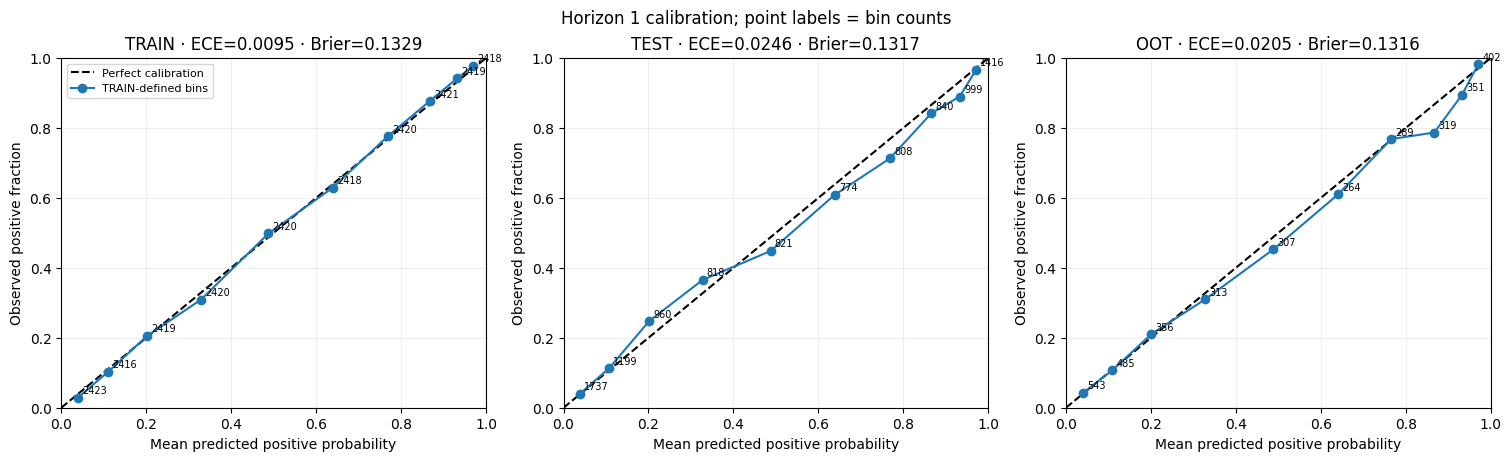

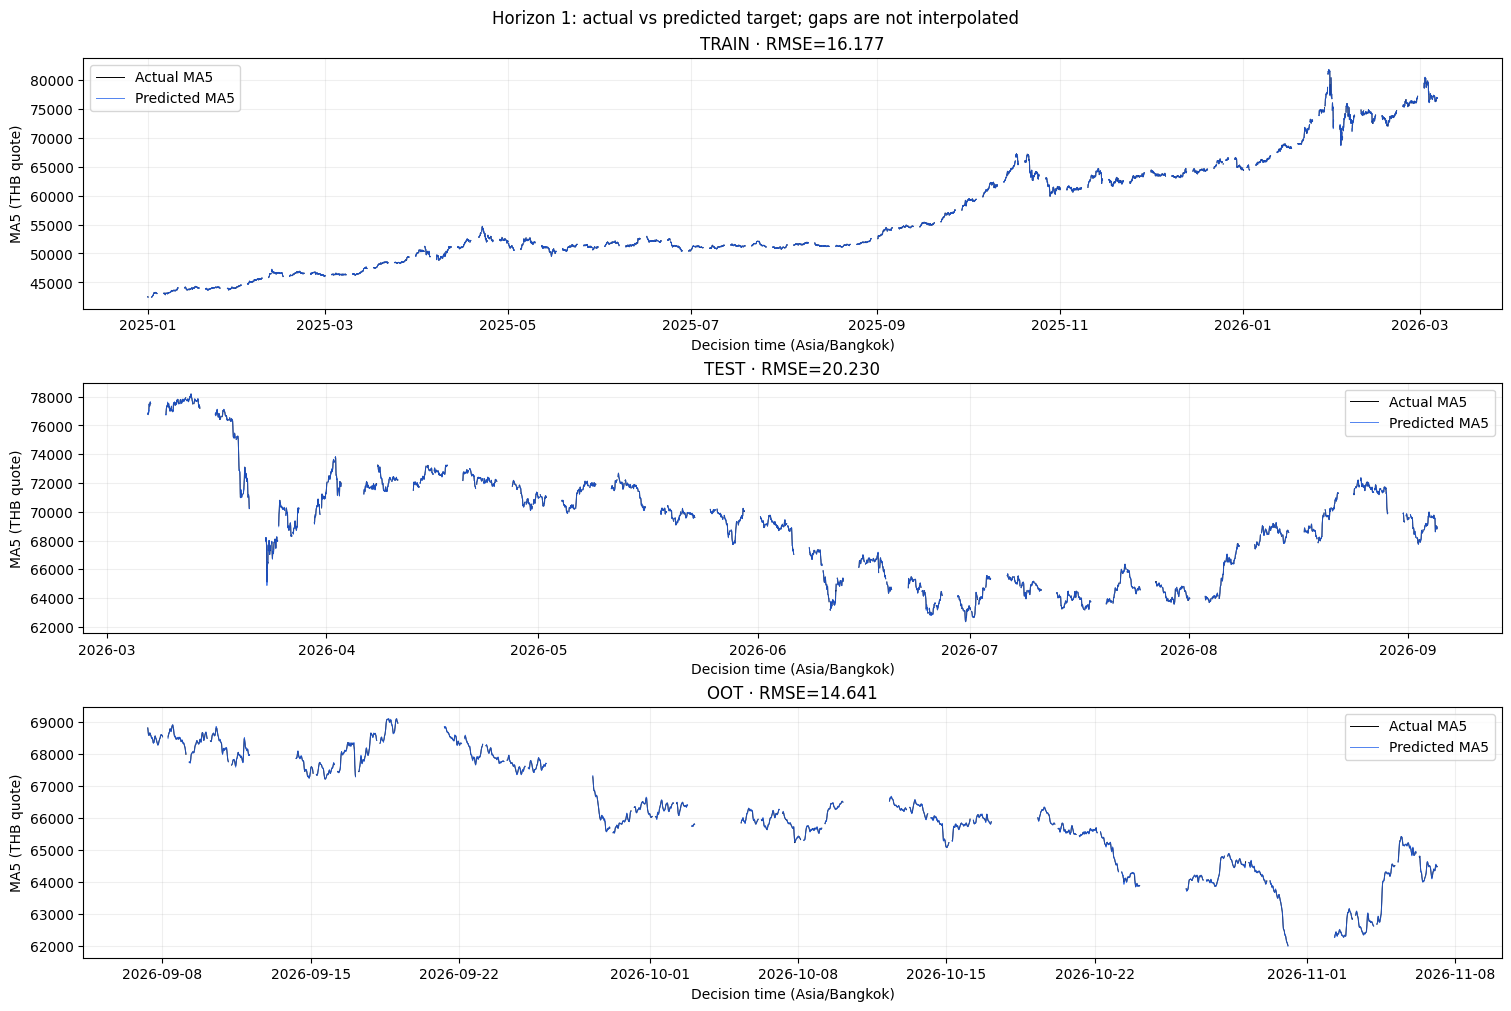

In [2]:
h=1
train_prob=predict(h,'classification','TRAIN')
internal=np.unique(np.quantile(train_prob,np.arange(.1,1,.1)))
internal=internal[(internal>0)&(internal<1)]
edges=np.r_[0.,internal,1.]
cutoff_rows.extend(dict(horizon=h,boundary=k,probability=float(v)) for k,v in enumerate(edges))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; prob=predict(h,'classification',part)
    y=(d.loc[i,f'y_h{h}'].to_numpy()>d.ma5_current.iloc[i].to_numpy()).astype(int)
    group=np.searchsorted(internal,prob,side='left')
    points=[]; ece=0.
    for k in range(len(edges)-1):
        take=group==k; n=int(take.sum())
        mp=float(prob[take].mean()) if n else np.nan
        rate=float(y[take].mean()) if n else np.nan
        weight=n/len(y); gap=abs(mp-rate) if n else 0.
        ece+=weight*gap
        bins.append(dict(horizon=h,partition=part,bin=k+1,lower=edges[k],upper=edges[k+1],n=n,weight=weight,mean_probability=mp,positive_rate=rate,absolute_gap=gap))
        if n: points.append((mp,rate,n))
    brier=float(np.mean((prob-y)**2)); summary.append(dict(horizon=h,partition=part,n=len(y),ECE=ece,Brier=brier))
    pts=np.asarray(points); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
    ax.plot(pts[:,0],pts[:,1],'-o',label='TRAIN-defined bins')
    for k,(mp,rate,n) in enumerate(points): ax.annotate(str(int(n)),(mp,rate),fontsize=7,xytext=(3,3),textcoords='offset points')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted positive probability',ylabel='Observed positive fraction',title=f'{part} · ECE={ece:.4f} · Brier={brier:.4f}')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8); fig.suptitle(f'Horizon {h} calibration; point labels = bin counts')
fig.savefig(OUT/f'h{h}_calibration.png',dpi=140); plt.show()
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; predicted=predict(h,'regression',part); actual=d.loc[i,f'y_h{h}'].to_numpy()
    dates=time.iloc[i].reset_index(drop=True); breaks=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(i))).groupby(breaks)):
        v=positions.to_numpy(); ax.plot(dates.iloc[v],actual[v],color='black',lw=.7,label='Actual MA5' if j==0 else None)
        ax.plot(dates.iloc[v],predicted[v],color='#2563eb',lw=.7,alpha=.8,label='Predicted MA5' if j==0 else None)
    rmse=np.sqrt(np.mean((actual-predicted)**2))
    ax.set(title=f'{part} · RMSE={rmse:.3f}',ylabel='MA5 (THB quote)',xlabel='Decision time (Asia/Bangkok)'); ax.legend(); ax.grid(alpha=.2)
fig.suptitle(f'Horizon {h}: actual vs predicted target; gaps are not interpolated')
fig.savefig(OUT/f'h{h}_regression.png',dpi=140); plt.show()


## Horizon 2: 30 minutes

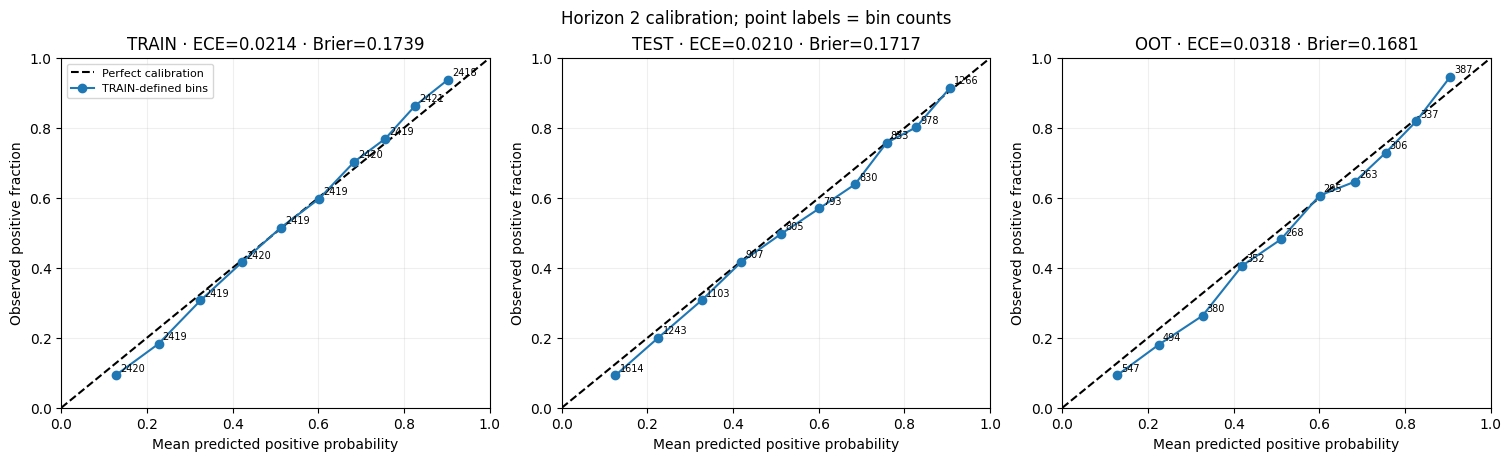

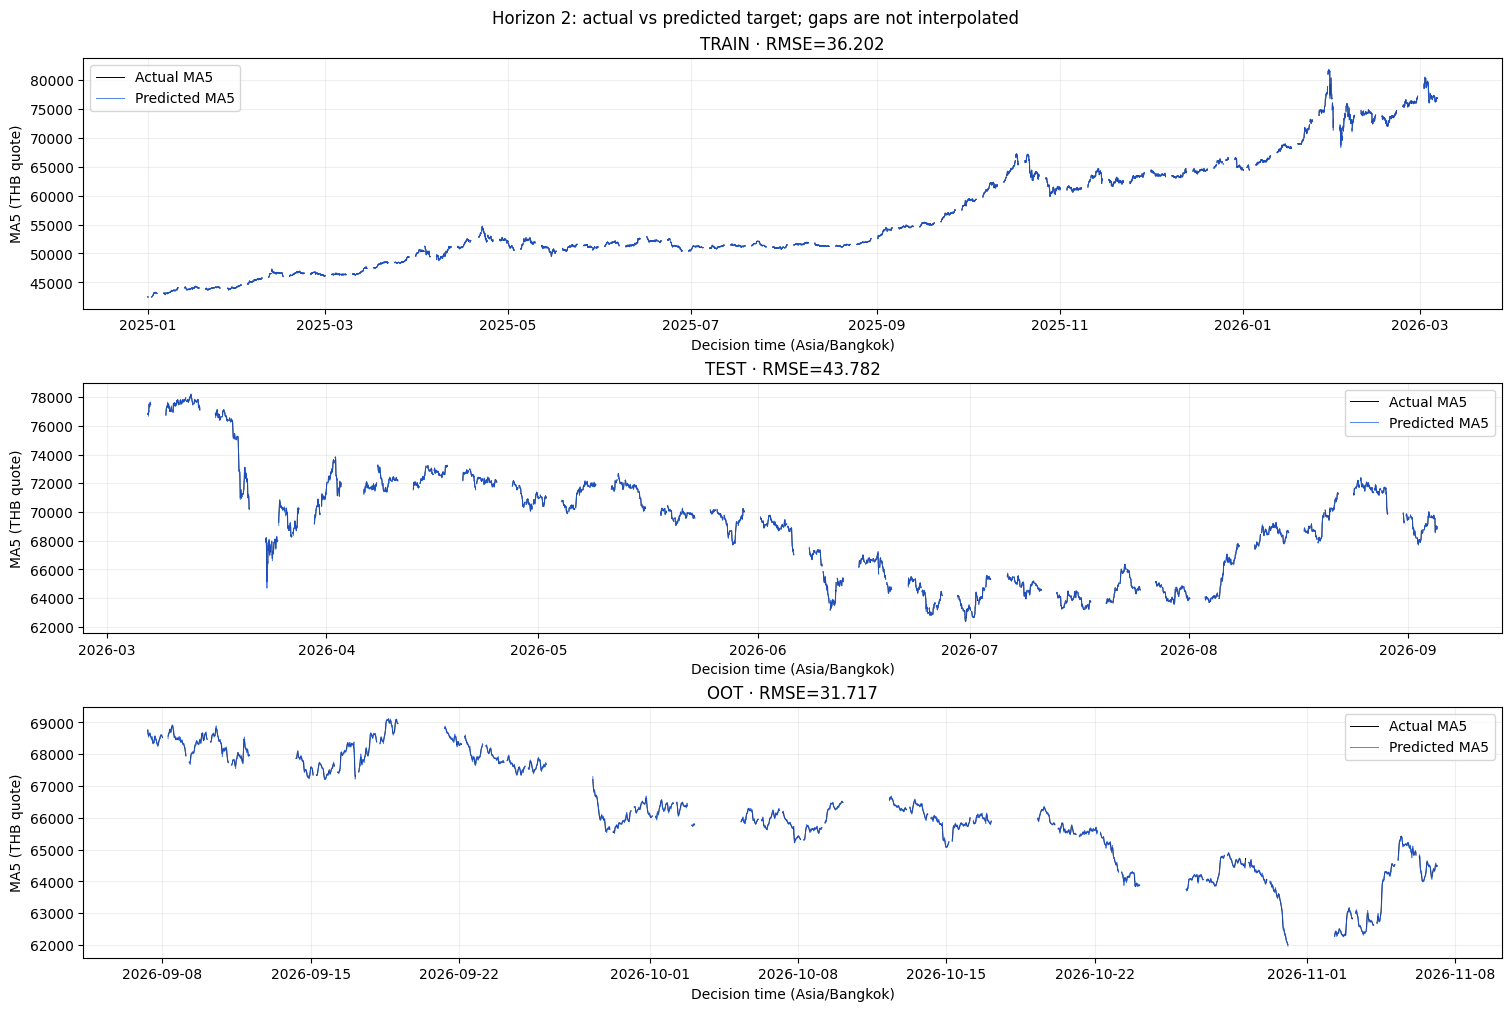

In [3]:
h=2
train_prob=predict(h,'classification','TRAIN')
internal=np.unique(np.quantile(train_prob,np.arange(.1,1,.1)))
internal=internal[(internal>0)&(internal<1)]
edges=np.r_[0.,internal,1.]
cutoff_rows.extend(dict(horizon=h,boundary=k,probability=float(v)) for k,v in enumerate(edges))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; prob=predict(h,'classification',part)
    y=(d.loc[i,f'y_h{h}'].to_numpy()>d.ma5_current.iloc[i].to_numpy()).astype(int)
    group=np.searchsorted(internal,prob,side='left')
    points=[]; ece=0.
    for k in range(len(edges)-1):
        take=group==k; n=int(take.sum())
        mp=float(prob[take].mean()) if n else np.nan
        rate=float(y[take].mean()) if n else np.nan
        weight=n/len(y); gap=abs(mp-rate) if n else 0.
        ece+=weight*gap
        bins.append(dict(horizon=h,partition=part,bin=k+1,lower=edges[k],upper=edges[k+1],n=n,weight=weight,mean_probability=mp,positive_rate=rate,absolute_gap=gap))
        if n: points.append((mp,rate,n))
    brier=float(np.mean((prob-y)**2)); summary.append(dict(horizon=h,partition=part,n=len(y),ECE=ece,Brier=brier))
    pts=np.asarray(points); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
    ax.plot(pts[:,0],pts[:,1],'-o',label='TRAIN-defined bins')
    for k,(mp,rate,n) in enumerate(points): ax.annotate(str(int(n)),(mp,rate),fontsize=7,xytext=(3,3),textcoords='offset points')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted positive probability',ylabel='Observed positive fraction',title=f'{part} · ECE={ece:.4f} · Brier={brier:.4f}')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8); fig.suptitle(f'Horizon {h} calibration; point labels = bin counts')
fig.savefig(OUT/f'h{h}_calibration.png',dpi=140); plt.show()
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; predicted=predict(h,'regression',part); actual=d.loc[i,f'y_h{h}'].to_numpy()
    dates=time.iloc[i].reset_index(drop=True); breaks=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(i))).groupby(breaks)):
        v=positions.to_numpy(); ax.plot(dates.iloc[v],actual[v],color='black',lw=.7,label='Actual MA5' if j==0 else None)
        ax.plot(dates.iloc[v],predicted[v],color='#2563eb',lw=.7,alpha=.8,label='Predicted MA5' if j==0 else None)
    rmse=np.sqrt(np.mean((actual-predicted)**2))
    ax.set(title=f'{part} · RMSE={rmse:.3f}',ylabel='MA5 (THB quote)',xlabel='Decision time (Asia/Bangkok)'); ax.legend(); ax.grid(alpha=.2)
fig.suptitle(f'Horizon {h}: actual vs predicted target; gaps are not interpolated')
fig.savefig(OUT/f'h{h}_regression.png',dpi=140); plt.show()


## Horizon 3: 45 minutes

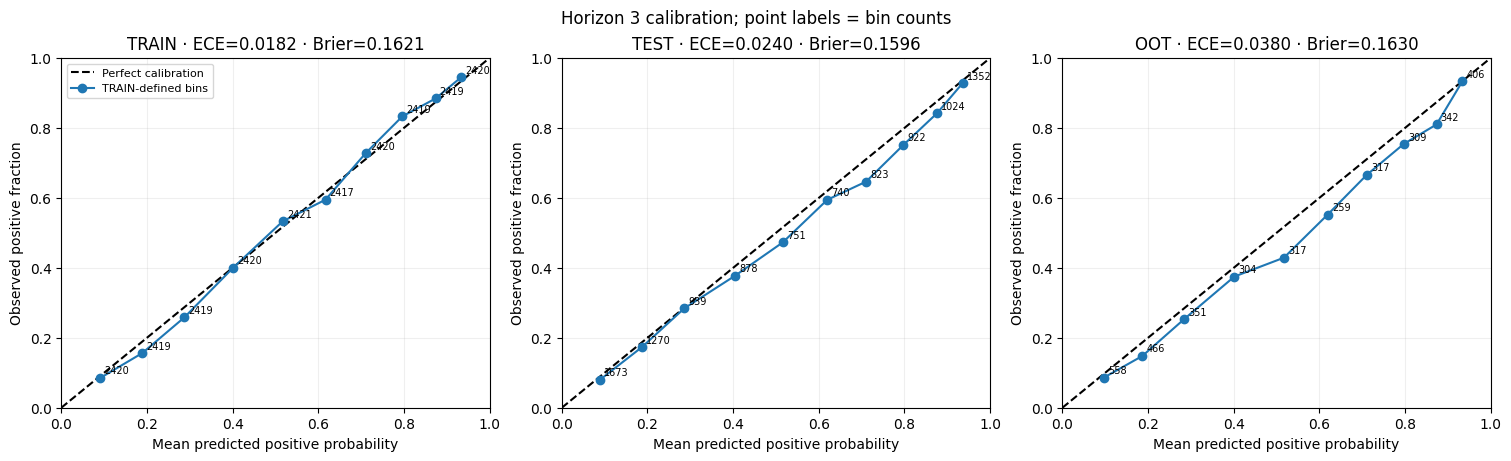

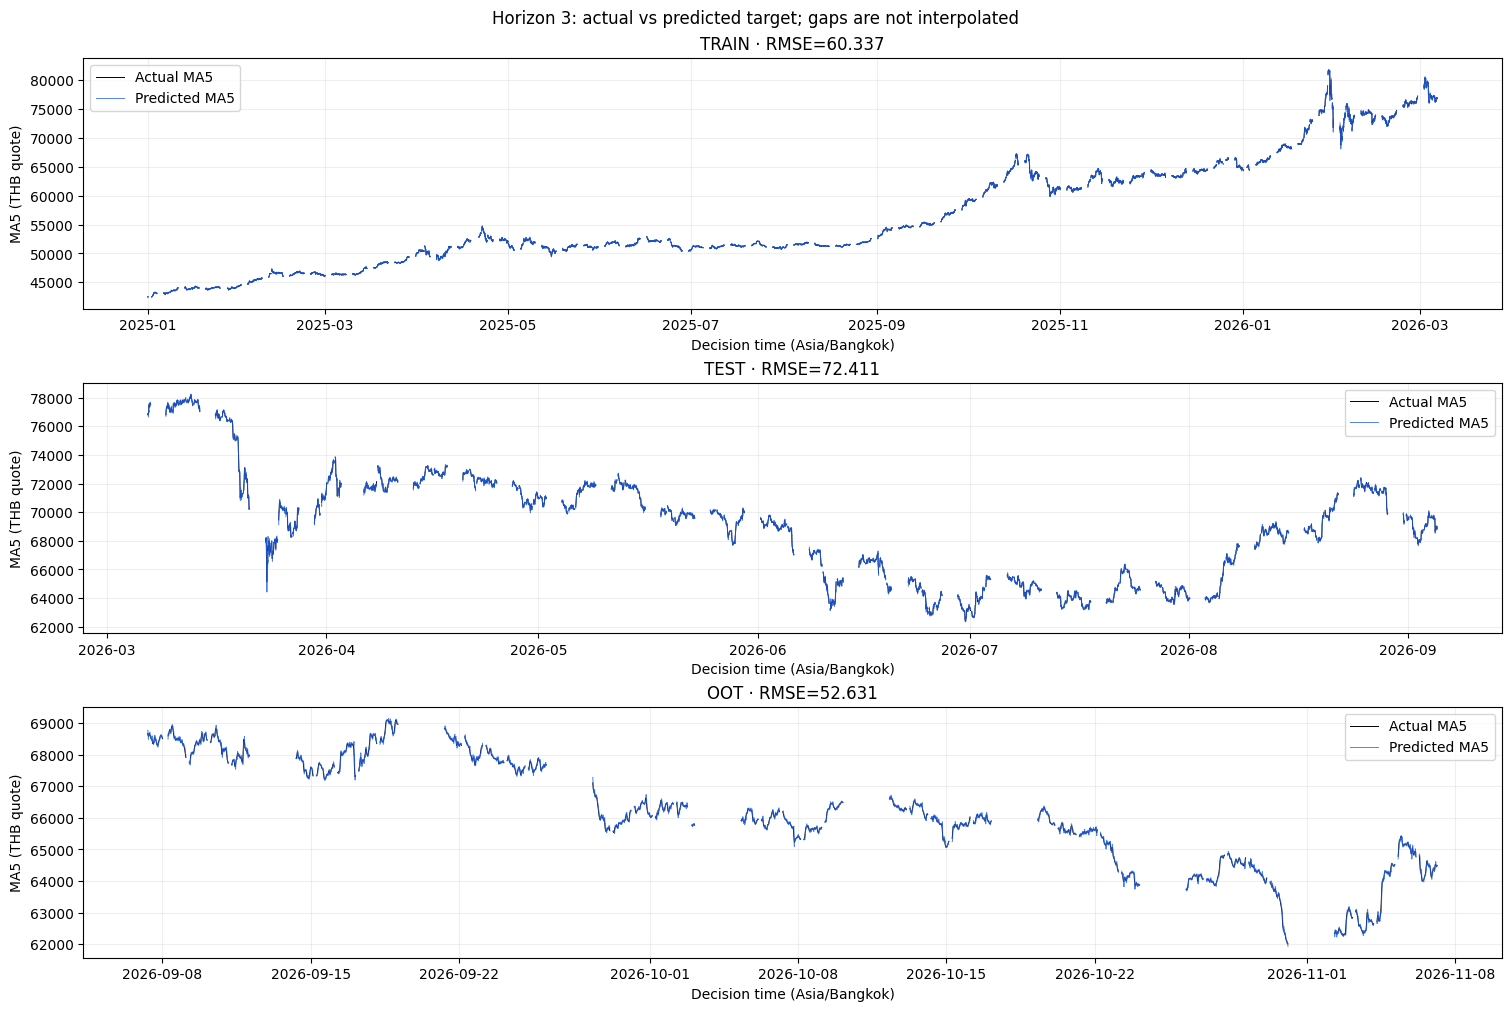

In [4]:
h=3
train_prob=predict(h,'classification','TRAIN')
internal=np.unique(np.quantile(train_prob,np.arange(.1,1,.1)))
internal=internal[(internal>0)&(internal<1)]
edges=np.r_[0.,internal,1.]
cutoff_rows.extend(dict(horizon=h,boundary=k,probability=float(v)) for k,v in enumerate(edges))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; prob=predict(h,'classification',part)
    y=(d.loc[i,f'y_h{h}'].to_numpy()>d.ma5_current.iloc[i].to_numpy()).astype(int)
    group=np.searchsorted(internal,prob,side='left')
    points=[]; ece=0.
    for k in range(len(edges)-1):
        take=group==k; n=int(take.sum())
        mp=float(prob[take].mean()) if n else np.nan
        rate=float(y[take].mean()) if n else np.nan
        weight=n/len(y); gap=abs(mp-rate) if n else 0.
        ece+=weight*gap
        bins.append(dict(horizon=h,partition=part,bin=k+1,lower=edges[k],upper=edges[k+1],n=n,weight=weight,mean_probability=mp,positive_rate=rate,absolute_gap=gap))
        if n: points.append((mp,rate,n))
    brier=float(np.mean((prob-y)**2)); summary.append(dict(horizon=h,partition=part,n=len(y),ECE=ece,Brier=brier))
    pts=np.asarray(points); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
    ax.plot(pts[:,0],pts[:,1],'-o',label='TRAIN-defined bins')
    for k,(mp,rate,n) in enumerate(points): ax.annotate(str(int(n)),(mp,rate),fontsize=7,xytext=(3,3),textcoords='offset points')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted positive probability',ylabel='Observed positive fraction',title=f'{part} · ECE={ece:.4f} · Brier={brier:.4f}')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8); fig.suptitle(f'Horizon {h} calibration; point labels = bin counts')
fig.savefig(OUT/f'h{h}_calibration.png',dpi=140); plt.show()
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; predicted=predict(h,'regression',part); actual=d.loc[i,f'y_h{h}'].to_numpy()
    dates=time.iloc[i].reset_index(drop=True); breaks=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(i))).groupby(breaks)):
        v=positions.to_numpy(); ax.plot(dates.iloc[v],actual[v],color='black',lw=.7,label='Actual MA5' if j==0 else None)
        ax.plot(dates.iloc[v],predicted[v],color='#2563eb',lw=.7,alpha=.8,label='Predicted MA5' if j==0 else None)
    rmse=np.sqrt(np.mean((actual-predicted)**2))
    ax.set(title=f'{part} · RMSE={rmse:.3f}',ylabel='MA5 (THB quote)',xlabel='Decision time (Asia/Bangkok)'); ax.legend(); ax.grid(alpha=.2)
fig.suptitle(f'Horizon {h}: actual vs predicted target; gaps are not interpolated')
fig.savefig(OUT/f'h{h}_regression.png',dpi=140); plt.show()


## Horizon 4: 60 minutes

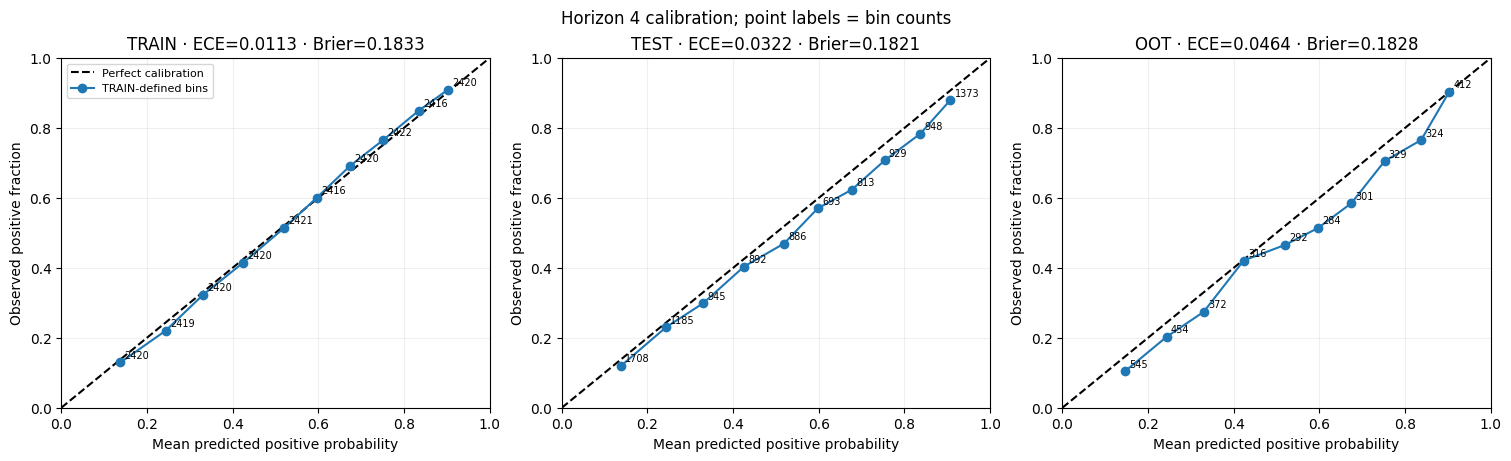

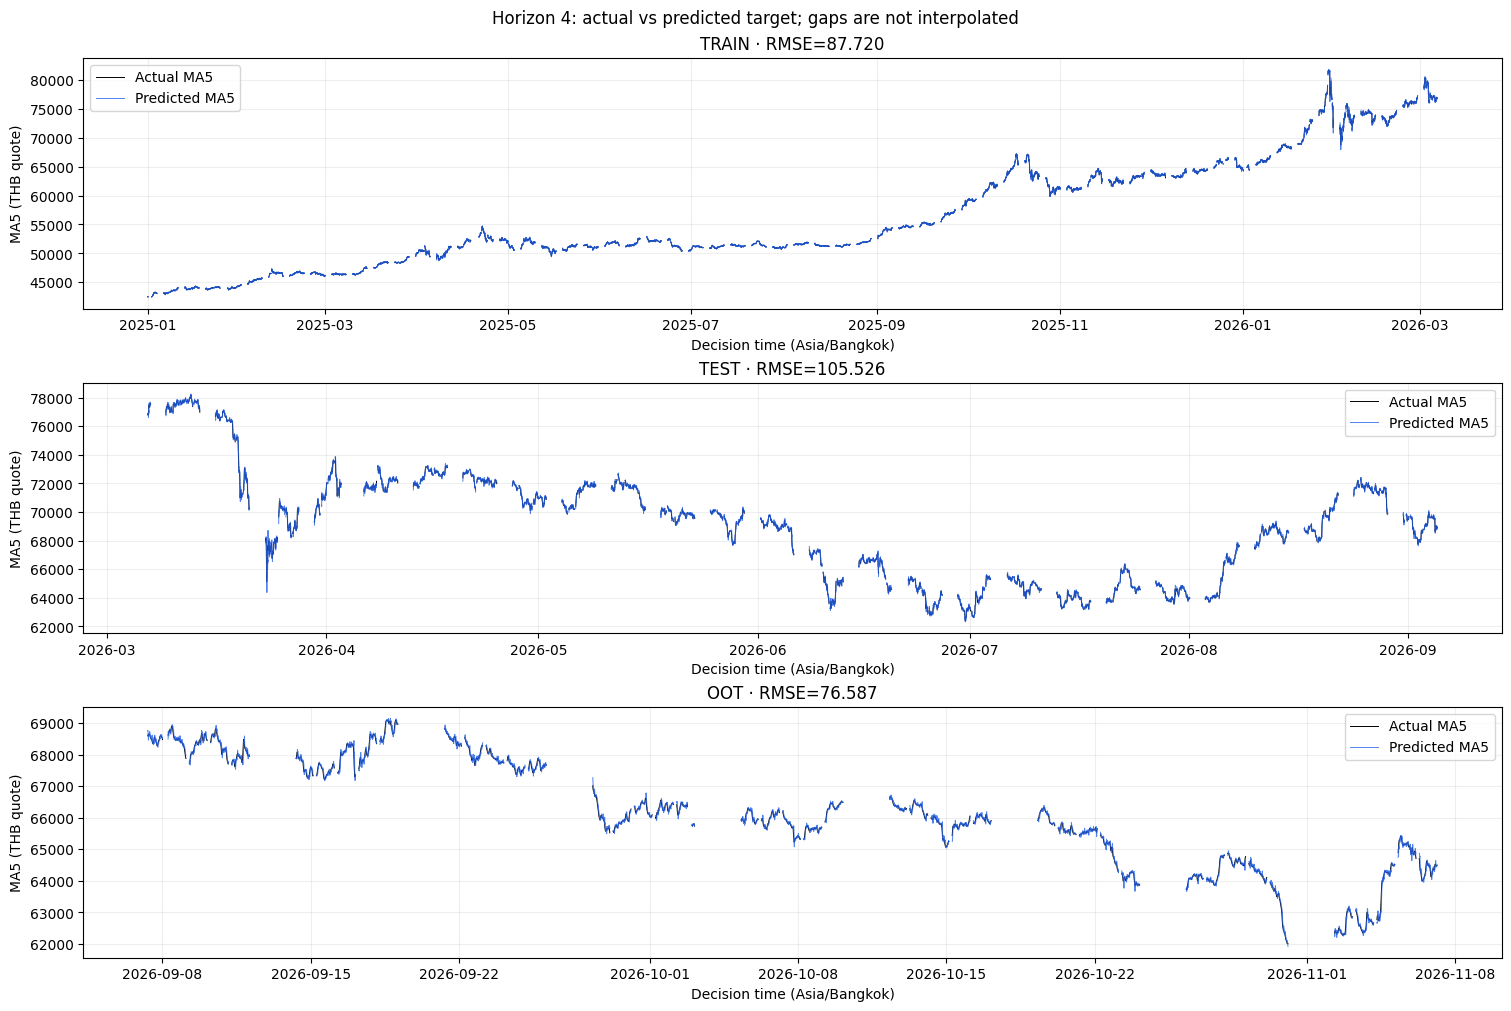

In [5]:
h=4
train_prob=predict(h,'classification','TRAIN')
internal=np.unique(np.quantile(train_prob,np.arange(.1,1,.1)))
internal=internal[(internal>0)&(internal<1)]
edges=np.r_[0.,internal,1.]
cutoff_rows.extend(dict(horizon=h,boundary=k,probability=float(v)) for k,v in enumerate(edges))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; prob=predict(h,'classification',part)
    y=(d.loc[i,f'y_h{h}'].to_numpy()>d.ma5_current.iloc[i].to_numpy()).astype(int)
    group=np.searchsorted(internal,prob,side='left')
    points=[]; ece=0.
    for k in range(len(edges)-1):
        take=group==k; n=int(take.sum())
        mp=float(prob[take].mean()) if n else np.nan
        rate=float(y[take].mean()) if n else np.nan
        weight=n/len(y); gap=abs(mp-rate) if n else 0.
        ece+=weight*gap
        bins.append(dict(horizon=h,partition=part,bin=k+1,lower=edges[k],upper=edges[k+1],n=n,weight=weight,mean_probability=mp,positive_rate=rate,absolute_gap=gap))
        if n: points.append((mp,rate,n))
    brier=float(np.mean((prob-y)**2)); summary.append(dict(horizon=h,partition=part,n=len(y),ECE=ece,Brier=brier))
    pts=np.asarray(points); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
    ax.plot(pts[:,0],pts[:,1],'-o',label='TRAIN-defined bins')
    for k,(mp,rate,n) in enumerate(points): ax.annotate(str(int(n)),(mp,rate),fontsize=7,xytext=(3,3),textcoords='offset points')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted positive probability',ylabel='Observed positive fraction',title=f'{part} · ECE={ece:.4f} · Brier={brier:.4f}')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8); fig.suptitle(f'Horizon {h} calibration; point labels = bin counts')
fig.savefig(OUT/f'h{h}_calibration.png',dpi=140); plt.show()
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; predicted=predict(h,'regression',part); actual=d.loc[i,f'y_h{h}'].to_numpy()
    dates=time.iloc[i].reset_index(drop=True); breaks=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(i))).groupby(breaks)):
        v=positions.to_numpy(); ax.plot(dates.iloc[v],actual[v],color='black',lw=.7,label='Actual MA5' if j==0 else None)
        ax.plot(dates.iloc[v],predicted[v],color='#2563eb',lw=.7,alpha=.8,label='Predicted MA5' if j==0 else None)
    rmse=np.sqrt(np.mean((actual-predicted)**2))
    ax.set(title=f'{part} · RMSE={rmse:.3f}',ylabel='MA5 (THB quote)',xlabel='Decision time (Asia/Bangkok)'); ax.legend(); ax.grid(alpha=.2)
fig.suptitle(f'Horizon {h}: actual vs predicted target; gaps are not interpolated')
fig.savefig(OUT/f'h{h}_regression.png',dpi=140); plt.show()


## Horizon 5: 75 minutes

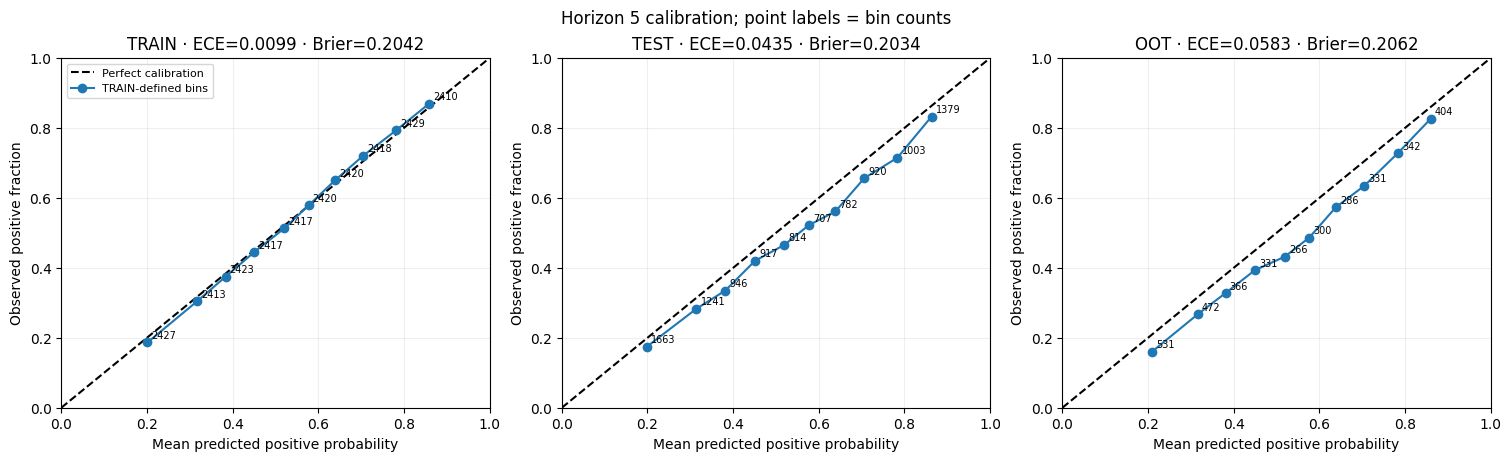

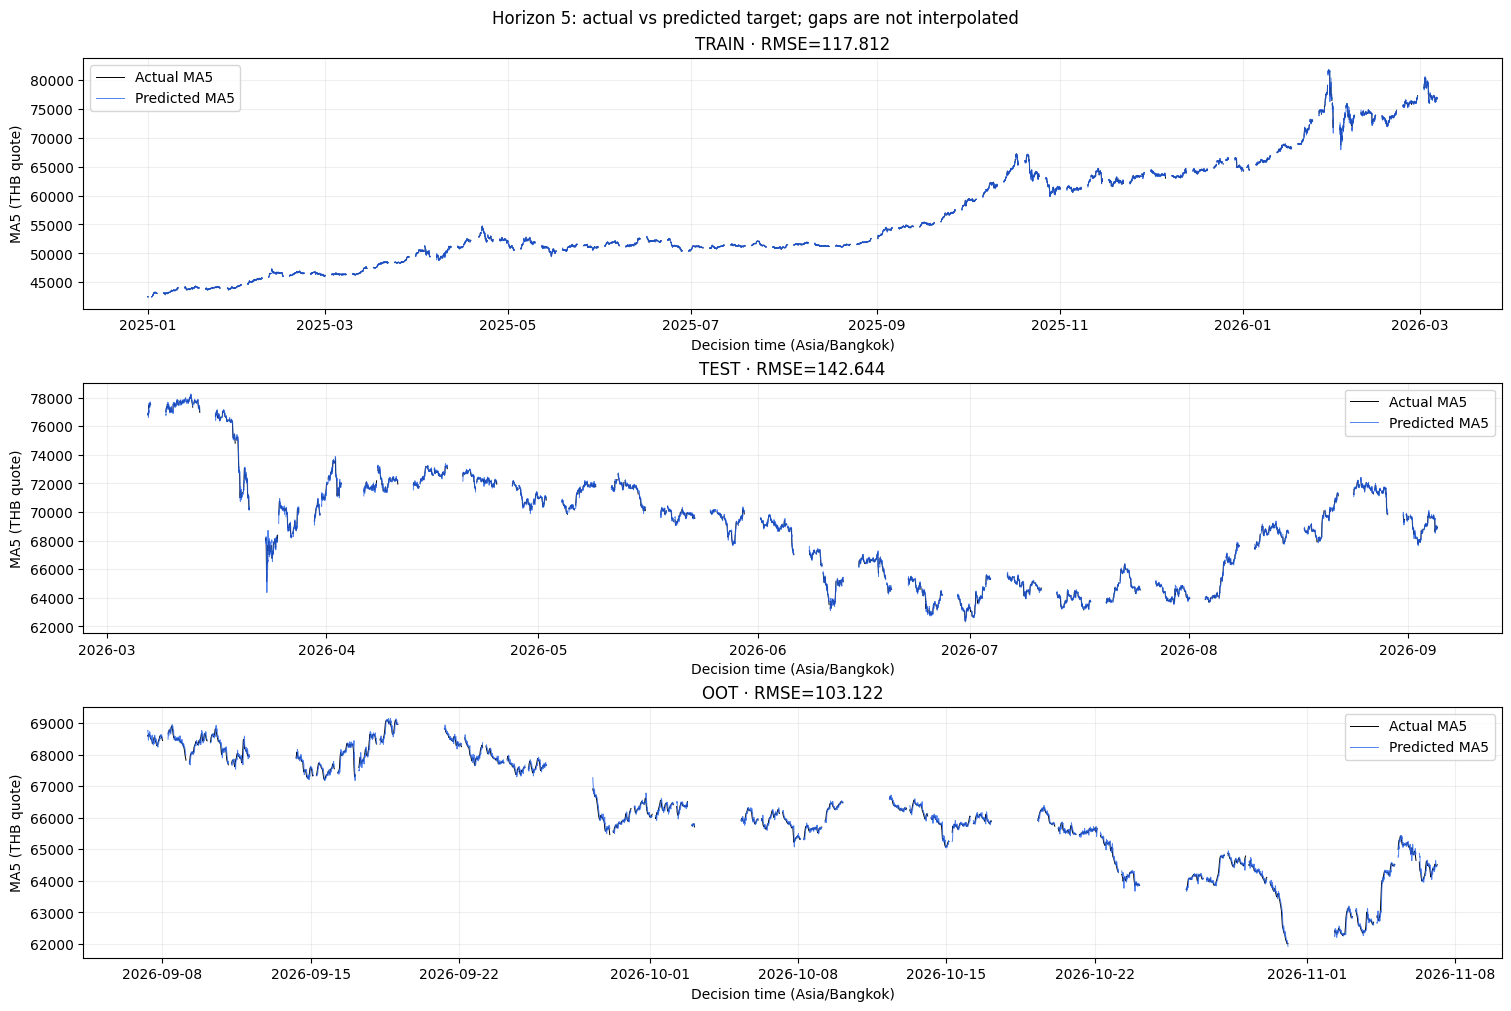

In [6]:
h=5
train_prob=predict(h,'classification','TRAIN')
internal=np.unique(np.quantile(train_prob,np.arange(.1,1,.1)))
internal=internal[(internal>0)&(internal<1)]
edges=np.r_[0.,internal,1.]
cutoff_rows.extend(dict(horizon=h,boundary=k,probability=float(v)) for k,v in enumerate(edges))
fig,axes=plt.subplots(1,3,figsize=(15,4.5),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; prob=predict(h,'classification',part)
    y=(d.loc[i,f'y_h{h}'].to_numpy()>d.ma5_current.iloc[i].to_numpy()).astype(int)
    group=np.searchsorted(internal,prob,side='left')
    points=[]; ece=0.
    for k in range(len(edges)-1):
        take=group==k; n=int(take.sum())
        mp=float(prob[take].mean()) if n else np.nan
        rate=float(y[take].mean()) if n else np.nan
        weight=n/len(y); gap=abs(mp-rate) if n else 0.
        ece+=weight*gap
        bins.append(dict(horizon=h,partition=part,bin=k+1,lower=edges[k],upper=edges[k+1],n=n,weight=weight,mean_probability=mp,positive_rate=rate,absolute_gap=gap))
        if n: points.append((mp,rate,n))
    brier=float(np.mean((prob-y)**2)); summary.append(dict(horizon=h,partition=part,n=len(y),ECE=ece,Brier=brier))
    pts=np.asarray(points); ax.plot([0,1],[0,1],'k--',label='Perfect calibration')
    ax.plot(pts[:,0],pts[:,1],'-o',label='TRAIN-defined bins')
    for k,(mp,rate,n) in enumerate(points): ax.annotate(str(int(n)),(mp,rate),fontsize=7,xytext=(3,3),textcoords='offset points')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted positive probability',ylabel='Observed positive fraction',title=f'{part} · ECE={ece:.4f} · Brier={brier:.4f}')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=8); fig.suptitle(f'Horizon {h} calibration; point labels = bin counts')
fig.savefig(OUT/f'h{h}_calibration.png',dpi=140); plt.show()
fig,axes=plt.subplots(3,1,figsize=(15,10),constrained_layout=True)
for ax,part in zip(axes,['TRAIN','TEST','OOT']):
    i=ids[part]; predicted=predict(h,'regression',part); actual=d.loc[i,f'y_h{h}'].to_numpy()
    dates=time.iloc[i].reset_index(drop=True); breaks=dates.diff().ne(pd.Timedelta(minutes=15)).cumsum()
    for j,(_,positions) in enumerate(pd.Series(np.arange(len(i))).groupby(breaks)):
        v=positions.to_numpy(); ax.plot(dates.iloc[v],actual[v],color='black',lw=.7,label='Actual MA5' if j==0 else None)
        ax.plot(dates.iloc[v],predicted[v],color='#2563eb',lw=.7,alpha=.8,label='Predicted MA5' if j==0 else None)
    rmse=np.sqrt(np.mean((actual-predicted)**2))
    ax.set(title=f'{part} · RMSE={rmse:.3f}',ylabel='MA5 (THB quote)',xlabel='Decision time (Asia/Bangkok)'); ax.legend(); ax.grid(alpha=.2)
fig.suptitle(f'Horizon {h}: actual vs predicted target; gaps are not interpolated')
fig.savefig(OUT/f'h{h}_regression.png',dpi=140); plt.show()


In [7]:
metrics=pd.DataFrame(summary); deciles=pd.DataFrame(bins)
metrics.to_csv(OUT/'ECE_Brier.csv',index=False)
deciles.to_csv(OUT/'decile_statistics.csv',index=False)
pd.DataFrame(cutoff_rows).to_csv(OUT/'train_probability_cutoffs.csv',index=False)
assert np.allclose(deciles.groupby(['horizon','partition']).weight.sum(),1)
display(metrics.pivot(index='horizon',columns='partition',values=['ECE','Brier']))

ECE                         Brier                    
partition       OOT      TEST     TRAIN       OOT      TEST     TRAIN
horizon                                                              
1          0.020451  0.024618  0.009519  0.131576  0.131709  0.132895
2          0.031848  0.021036  0.021399  0.168118  0.171708  0.173937
3          0.037987  0.024040  0.018245  0.162994  0.159585  0.162067
4          0.046440  0.032197  0.011316  0.182837  0.182056  0.183316
5          0.058326  0.043507  0.009945  0.206239  0.203425  0.204172